In [1]:
import os
import sys
import glob
import json
import time
import random
import copy
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable a GPU from Runtime > Change runtime type.")

PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


In [3]:

from pathlib import Path

# Kaggle datasets attached using "Add Input"
DATASET_ROOT = Path("/kaggle/input")

csv_candidates = list(DATASET_ROOT.rglob("FileList.csv"))

video_dirs = [
    p for p in DATASET_ROOT.rglob("Videos")
    if p.is_dir()
]

print("FileList.csv files found:")
for p in csv_candidates[:20]:
    print(p)

print("\nVideos folders found:")
for p in video_dirs[:20]:
    print(p)

if not csv_candidates:
    raise FileNotFoundError(
        "FileList.csv was not found. "
        "Check that EchoNet-Dynamic is attached using Add Input."
    )

if not video_dirs:
    raise FileNotFoundError(
        "Videos folder was not found. "
        "Check the dataset folder structure in Kaggle."
    )


FileList.csv files found:
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/FileList.csv

Videos folders found:
/kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos


In [4]:
if len(csv_candidates) == 0:
    raise FileNotFoundError(
        "FileList.csv was not found in MyDrive. "
        "Place the official metadata CSV in Drive or set CSV_PATH manually."
    )

if len(video_dirs) == 0:
    raise FileNotFoundError(
        "A Videos folder was not found in MyDrive. "
        "Extract the EchoNet-Dynamic videos or set VIDEO_DIR manually."
    )

CSV_PATH = csv_candidates[0]
VIDEO_DIR = video_dirs[0]

# If there are multiple copies, replace the paths above, for example:
# CSV_PATH = Path("/content/drive/MyDrive/EchoNet-Dynamic/FileList.csv")
# VIDEO_DIR = Path("/content/drive/MyDrive/EchoNet-Dynamic/Videos")

print("Selected CSV:", CSV_PATH)
print("Selected video directory:", VIDEO_DIR)

Selected CSV: /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/FileList.csv
Selected video directory: /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos


In [5]:
df = pd.read_csv(CSV_PATH)
df.columns = [str(c).strip() for c in df.columns]

print("Metadata shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

column_lookup = {c.lower(): c for c in df.columns}

required = ["filename", "ef", "split"]
missing = [c for c in required if c not in column_lookup]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}. "
        f"Found columns: {df.columns.tolist()}"
    )

rename_map = {
    column_lookup["filename"]: "FileName",
    column_lookup["ef"]: "EF",
    column_lookup["split"]: "Split"
}

if "esv" in column_lookup:
    rename_map[column_lookup["esv"]] = "ESV"

if "edv" in column_lookup:
    rename_map[column_lookup["edv"]] = "EDV"

df = df.rename(columns=rename_map)

print("\nSplit distribution:")
display(df["Split"].value_counts().to_frame("Video_count"))

print("\nEF statistics:")
display(df["EF"].describe().to_frame())

Metadata shape: (10030, 9)
Columns: ['FileName', 'EF', 'ESV', 'EDV', 'FrameHeight', 'FrameWidth', 'FPS', 'NumberOfFrames', 'Split']


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL



Split distribution:


,Video_count
Split,
TRAIN,7465
VAL,1288
TEST,1277



EF statistics:


,EF
count,10030.000000
mean,55.748248
std,12.371483
min,6.907258
25%,51.601387
50%,59.209109
75%,63.958740
max,96.967237


In [6]:
# Reload the metadata to ensure we start with a clean DataFrame on re-runs
df = pd.read_csv(CSV_PATH)
df.columns = [str(c).strip() for c in df.columns]

column_lookup = {c.lower(): c for c in df.columns}
rename_map = {
    column_lookup["filename"]: "FileName",
    column_lookup["ef"]: "EF",
    column_lookup["split"]: "Split"
}
if "esv" in column_lookup:
    rename_map[column_lookup["esv"]] = "ESV"
if "edv" in column_lookup:
    rename_map[column_lookup["edv"]] = "EDV"
df = df.rename(columns=rename_map)

df["FileName"] = df["FileName"].astype(str).str.strip()
df["Split"] = df["Split"].astype(str).str.strip().str.upper()
df["EF"] = pd.to_numeric(df["EF"], errors="coerce")

before_cleaning = len(df)

df = df.dropna(subset=["FileName", "EF", "Split"]).copy()
df = df[df["FileName"] != ""].copy()
df = df[df["EF"].between(0, 100)].copy()
df = df[df["Split"].isin(["TRAIN", "VAL", "TEST"])].copy()
df = df.drop_duplicates(subset=["FileName"], keep="first").copy()

video_extensions = {".avi", ".mp4", ".mov", ".mkv"}
video_lookup = {}

for p in VIDEO_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in video_extensions:
        filename_lower = p.name.lower()
        # Save both full filename and filename without extension as keys for robust matching
        video_lookup[filename_lower] = str(p)
        video_lookup[p.stem.lower()] = str(p)

def match_video(name):
    name_clean = Path(name).name.lower()
    # Try exact match
    if name_clean in video_lookup:
        return video_lookup[name_clean]
    # Try matching without extension if name has one
    stem_clean = Path(name).stem.lower()
    if stem_clean in video_lookup:
        return video_lookup[stem_clean]
    return None

df["VideoPath"] = df["FileName"].apply(match_video)

missing_mask = df["VideoPath"].isna()

print("Rows before cleaning:", before_cleaning)
print("Rows without valid labels/splits removed:", before_cleaning - len(df))
print("Rows with video files missing:", int(missing_mask.sum()))

if missing_mask.any():
    display(df.loc[missing_mask, ["FileName", "EF", "Split"]].head(10))

df = df.loc[~missing_mask].copy()

if df.empty:
    raise ValueError("No valid videos remain after matching the metadata.")

if not {"TRAIN", "VAL", "TEST"}.issubset(set(df["Split"])):
    raise ValueError(
        "TRAIN, VAL, and TEST were not all found. "
        "Check the selected metadata and video folder."
    )

if not df["FileName"].is_unique:
    raise ValueError("Duplicate video IDs remain after cleaning.")

print("\nClean dataset:", df.shape)
display(df["Split"].value_counts().to_frame("Videos"))
print("EF range:", df["EF"].min(), "to", df["EF"].max())

Rows before cleaning: 10030
Rows without valid labels/splits removed: 0
Rows with video files missing: 0

Clean dataset: (10030, 10)


,Videos
Split,
TRAIN,7465
VAL,1288
TEST,1277


EF range: 6.907258122 to 96.96723658


In [7]:
NUM_FRAMES = 16
IMAGE_SIZE = 112
BATCH_SIZE = 4
NUM_WORKERS = 2
EPOCHS = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/EchoNet_EF_Experiment_16frames"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(OUTPUT_DIR / "cleaned_video_manifest.csv", index=False)

train_df = df[df["Split"] == "TRAIN"].reset_index(drop=True)
val_df = df[df["Split"] == "VAL"].reset_index(drop=True)
test_df = df[df["Split"] == "TEST"].reset_index(drop=True)

print("Train videos:", len(train_df))
print("Validation videos:", len(val_df))
print("Test videos:", len(test_df))
print("Frames per video:", NUM_FRAMES)
print("Image size:", IMAGE_SIZE)
print("Outputs:", OUTPUT_DIR)

Train videos: 7465
Validation videos: 1288
Test videos: 1277
Frames per video: 16
Image size: 112
Outputs: /content/drive/MyDrive/EchoNet_EF_Experiment_16frames


In [8]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

frame_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class EchoVideoDataset(Dataset):
    def __init__(self, metadata, num_frames=16, transform=None):
        self.data = metadata.reset_index(drop=True).copy()
        self.num_frames = num_frames
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        video_path = row["VideoPath"]

        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            raise RuntimeError(f"Cannot open video: {video_path}")

        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames < 1:
            cap.release()
            raise RuntimeError(f"Invalid video frame count: {video_path}")

        frame_indices = np.linspace(
            0, total_frames - 1, self.num_frames
        ).round().astype(int)

        frames = []

        for frame_index in frame_indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
            ok, frame = cap.read()

            if not ok or frame is None:
                cap.release()
                raise RuntimeError(
                    f"Failed to read frame {frame_index}: {video_path}"
                )

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            if self.transform is not None:
                frame = self.transform(frame)

            frames.append(frame)

        cap.release()

        # [T, C, H, W]
        frames = torch.stack(frames)
        ef = torch.tensor(float(row["EF"]), dtype=torch.float32)

        return {
            "frames": frames,
            "EF": ef,
            "FileName": row["FileName"]
        }


train_dataset = EchoVideoDataset(train_df, NUM_FRAMES, frame_transform)
val_dataset = EchoVideoDataset(val_df, NUM_FRAMES, frame_transform)
test_dataset = EchoVideoDataset(test_df, NUM_FRAMES, frame_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

print("Datasets and DataLoaders are ready.")

Datasets and DataLoaders are ready.


In [9]:
sample = train_dataset[0]

print("Sample video:", sample["FileName"])
print("Frame tensor shape:", tuple(sample["frames"].shape))
print("EF target:", sample["EF"].item())

batch = next(iter(train_loader))
print("\nBatch shape:", tuple(batch["frames"].shape))
print("Batch EF shape:", tuple(batch["EF"].shape))
print("Video IDs:", batch["FileName"])

assert batch["frames"].shape[1:] == (
    NUM_FRAMES, 3, IMAGE_SIZE, IMAGE_SIZE
)
assert batch["EF"].shape[0] == batch["frames"].shape[0]

print("Data pipeline checks passed.")

Sample video: 0X1002E8FBACD08477
Frame tensor shape: (16, 3, 112, 112)
EF target: 59.10198974609375

Batch shape: (4, 16, 3, 112, 112)
Batch EF shape: (4,)
Video IDs: ['0X24C59DA367132337', '0X758AD34A442E9B92', '0X21B497B1AE639C14', '0X6769A9060D724375']
Data pipeline checks passed.


In [10]:
def build_mobilenet_backbone():
    try:
        weights = models.MobileNet_V3_Small_Weights.DEFAULT
        net = models.mobilenet_v3_small(weights=weights)
        print("ImageNet pretrained weights loaded.")
    except Exception as e:
        print("Pretrained weights unavailable:", str(e))
        print("Using randomly initialized weights.")
        net = models.mobilenet_v3_small(weights=None)

    feature_dim = net.classifier[0].in_features

    backbone = nn.Sequential(
        net.features,
        net.avgpool,
        nn.Flatten(start_dim=1)
    )

    return backbone, feature_dim

In [11]:
class EchoEFModel(nn.Module):
    def __init__(self, temporal="bilstm", hidden_size=128, dropout=0.3):
        super().__init__()

        if temporal not in {"average", "bilstm"}:
            raise ValueError("temporal must be 'average' or 'bilstm'")

        self.temporal = temporal
        self.backbone, feature_dim = build_mobilenet_backbone()

        if temporal == "bilstm":
            self.temporal_model = nn.LSTM(
                input_size=feature_dim,
                hidden_size=hidden_size,
                num_layers=1,
                batch_first=True,
                bidirectional=True
            )
            head_dim = hidden_size * 2
        else:
            self.temporal_model = None
            head_dim = feature_dim

        self.regressor = nn.Sequential(
            nn.Linear(head_dim, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )

    def forward(self, video):
        # video: [B, T, C, H, W]
        b, t, c, h, w = video.shape

        frames = video.reshape(b * t, c, h, w)
        frame_features = self.backbone(frames)
        frame_features = frame_features.reshape(b, t, -1)

        if self.temporal == "bilstm":
            sequence_features, _ = self.temporal_model(frame_features)
            video_features = sequence_features.mean(dim=1)
        else:
            video_features = frame_features.mean(dim=1)

        # Exactly one prediction per video.
        return self.regressor(video_features).squeeze(1)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


check_model = EchoEFModel("bilstm").to(DEVICE)
sample_batch = next(iter(train_loader))
with torch.no_grad():
    output = check_model(sample_batch["frames"].to(DEVICE))

print("Output shape:", tuple(output.shape))
print("Expected:", (sample_batch["frames"].shape[0],))
print("Trainable parameters:", f"{count_parameters(check_model):,}")

assert output.shape == (sample_batch["frames"].shape[0],)

del check_model, sample_batch, output
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 191MB/s]

ImageNet pretrained weights loaded.


Output shape: (4,)
Expected: (4,)
Trainable parameters: 1,682,977


In [12]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    targets_all, predictions_all = [], []

    for batch in loader:
        frames = batch["frames"].to(DEVICE, non_blocking=True)
        targets = batch["EF"].to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            predictions = model(frames)
            loss = criterion(predictions, targets)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        total_loss += loss.item() * len(targets)
        targets_all.extend(targets.detach().cpu().numpy())
        predictions_all.extend(predictions.detach().cpu().numpy())

    targets_all = np.asarray(targets_all, dtype=np.float64)
    predictions_all = np.asarray(predictions_all, dtype=np.float64)

    return {
        "loss": total_loss / max(len(targets_all), 1),
        "mae": mean_absolute_error(targets_all, predictions_all),
        "rmse": np.sqrt(mean_squared_error(targets_all, predictions_all)),
        "targets": targets_all,
        "predictions": predictions_all
    }


def train_model(temporal, model_name):
    model = EchoEFModel(temporal=temporal).to(DEVICE)

    criterion = nn.SmoothL1Loss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    checkpoint_path = OUTPUT_DIR / f"{model_name}_best.pt"
    history = []
    best_val_mae = float("inf")
    no_improvement = 0

    print(f"\nTraining {model_name}")
    print("Trainable parameters:", f"{count_parameters(model):,}")

    for epoch in range(1, EPOCHS + 1):
        start = time.time()

        train_metrics = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_metrics = run_epoch(
            model, val_loader, criterion
        )

        scheduler.step(val_metrics["mae"])
        elapsed = time.time() - start

        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_mae": train_metrics["mae"],
            "val_loss": val_metrics["loss"],
            "val_mae": val_metrics["mae"],
            "val_rmse": val_metrics["rmse"],
            "learning_rate": optimizer.param_groups[0]["lr"],
            "seconds": elapsed
        }
        history.append(row)

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train MAE {train_metrics['mae']:.3f} | "
            f"Val MAE {val_metrics['mae']:.3f} | "
            f"Val RMSE {val_metrics['rmse']:.3f} | "
            f"{elapsed:.1f}s"
        )

        if val_metrics["mae"] < best_val_mae:
            best_val_mae = val_metrics["mae"]
            no_improvement = 0

            torch.save({
                "model_state_dict": model.state_dict(),
                "temporal": temporal,
                "num_frames": NUM_FRAMES,
                "image_size": IMAGE_SIZE,
                "best_val_mae": best_val_mae,
                "seed": SEED
            }, checkpoint_path)

            print("  Best checkpoint saved.")
        else:
            no_improvement += 1

        if no_improvement >= PATIENCE:
            print("Early stopping.")
            break

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        OUTPUT_DIR / f"{model_name}_history.csv", index=False
    )

    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])

    return model, history_df, str(checkpoint_path)

In [13]:
average_model, average_history, average_checkpoint = train_model(
    temporal="average",
    model_name="mobilenetv3_average"
)

print("Best baseline validation MAE:", average_history["val_mae"].min())
print("Checkpoint:", average_checkpoint)

ImageNet pretrained weights loaded.

Training mobilenetv3_average
Trainable parameters: 1,000,993
Epoch 01/20 | Train MAE 15.353 | Val MAE 8.243 | Val RMSE 11.336 | 220.6s
  Best checkpoint saved.
Epoch 02/20 | Train MAE 8.654 | Val MAE 8.288 | Val RMSE 11.046 | 198.1s
Epoch 03/20 | Train MAE 8.358 | Val MAE 8.188 | Val RMSE 11.030 | 204.5s
  Best checkpoint saved.
Epoch 04/20 | Train MAE 8.083 | Val MAE 8.345 | Val RMSE 11.669 | 202.9s
Epoch 05/20 | Train MAE 8.004 | Val MAE 7.202 | Val RMSE 10.100 | 202.0s
  Best checkpoint saved.
Epoch 06/20 | Train MAE 7.875 | Val MAE 7.296 | Val RMSE 10.160 | 195.9s
Epoch 07/20 | Train MAE 7.630 | Val MAE 6.996 | Val RMSE 9.868 | 195.9s
  Best checkpoint saved.
Epoch 08/20 | Train MAE 7.512 | Val MAE 6.677 | Val RMSE 9.743 | 201.6s
  Best checkpoint saved.
Epoch 09/20 | Train MAE 7.388 | Val MAE 7.100 | Val RMSE 10.268 | 195.2s
Epoch 10/20 | Train MAE 7.249 | Val MAE 6.952 | Val RMSE 10.090 | 194.1s
Epoch 11/20 | Train MAE 7.107 | Val MAE 7.934 | 

In [15]:
bilstm_model, bilstm_history, bilstm_checkpoint = train_model(
    temporal="bilstm",
    model_name="mobilenetv3_bilstm"
)

print("Best BiLSTM validation MAE:", bilstm_history["val_mae"].min())
print("Checkpoint:", bilstm_checkpoint)

ImageNet pretrained weights loaded.

Training mobilenetv3_bilstm
Trainable parameters: 1,682,977
Epoch 01/20 | Train MAE 16.044 | Val MAE 8.285 | Val RMSE 10.744 | 188.0s
  Best checkpoint saved.
Epoch 02/20 | Train MAE 8.440 | Val MAE 6.930 | Val RMSE 9.608 | 187.4s
  Best checkpoint saved.
Epoch 03/20 | Train MAE 7.779 | Val MAE 6.320 | Val RMSE 8.797 | 189.0s
  Best checkpoint saved.
Epoch 04/20 | Train MAE 7.355 | Val MAE 6.429 | Val RMSE 8.612 | 188.0s
Epoch 05/20 | Train MAE 7.028 | Val MAE 5.980 | Val RMSE 8.082 | 189.1s
  Best checkpoint saved.
Epoch 06/20 | Train MAE 6.901 | Val MAE 6.212 | Val RMSE 8.395 | 190.2s
Epoch 07/20 | Train MAE 6.635 | Val MAE 5.812 | Val RMSE 7.948 | 190.8s
  Best checkpoint saved.
Epoch 08/20 | Train MAE 6.583 | Val MAE 5.444 | Val RMSE 7.644 | 191.1s
  Best checkpoint saved.
Epoch 09/20 | Train MAE 6.302 | Val MAE 5.877 | Val RMSE 7.924 | 189.2s
Epoch 10/20 | Train MAE 6.291 | Val MAE 5.696 | Val RMSE 7.875 | 188.5s
Epoch 11/20 | Train MAE 6.102 |

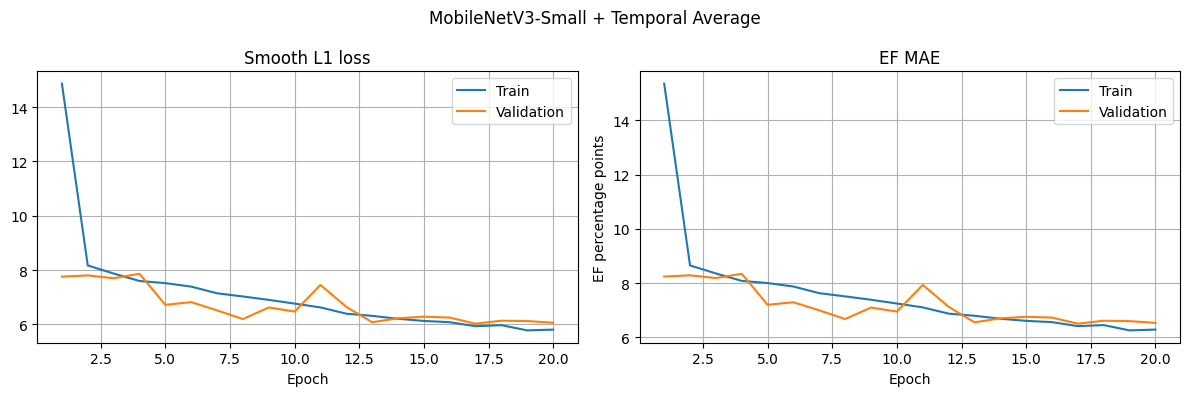

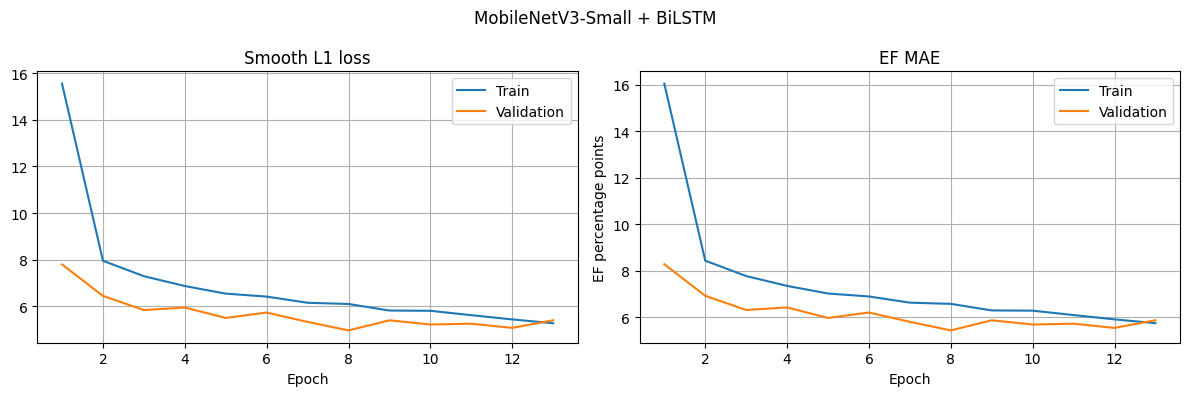

In [16]:
def plot_history(history_df, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
    axes[0].set_title("Smooth L1 loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(history_df["epoch"], history_df["train_mae"], label="Train")
    axes[1].plot(history_df["epoch"], history_df["val_mae"], label="Validation")
    axes[1].set_title("EF MAE")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("EF percentage points")
    axes[1].legend()
    axes[1].grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(average_history, "MobileNetV3-Small + Temporal Average")
plot_history(bilstm_history, "MobileNetV3-Small + BiLSTM")

In [17]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)

    if len(y_true) == 0:
        raise ValueError("No test predictions were generated.")

    if len(y_true) > 1 and np.std(y_true) > 0 and np.std(y_pred) > 0:
        pearson_r = float(np.corrcoef(y_true, y_pred)[0, 1])
    else:
        pearson_r = np.nan

    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MSE": float(mean_squared_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)),
        "Pearson_r": pearson_r,
        "Within_5_EF_points_percent": float(
            100 * np.mean(np.abs(y_true - y_pred) <= 5)
        )
    }


def evaluate_test_set(model, loader, model_name):
    model.eval()

    y_true, y_pred, names = [], [], []
    forward_seconds = 0.0

    with torch.no_grad():
        for batch in loader:
            frames = batch["frames"].to(DEVICE, non_blocking=True)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()

            predictions = model(frames)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            forward_seconds += time.perf_counter() - start

            y_true.extend(batch["EF"].numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())
            names.extend(list(batch["FileName"]))

    metrics = calculate_metrics(y_true, y_pred)
    metrics["Model"] = model_name
    metrics["Test_videos"] = len(y_true)
    metrics["Forward_seconds_total"] = forward_seconds
    metrics["Forward_ms_per_video"] = (
        1000 * forward_seconds / max(len(y_true), 1)
    )

    predictions_df = pd.DataFrame({
        "FileName": names,
        "EF_true": y_true,
        "EF_predicted": y_pred
    })
    predictions_df["Absolute_error"] = (
        predictions_df["EF_true"] - predictions_df["EF_predicted"]
    ).abs()

    predictions_df.to_csv(
        OUTPUT_DIR / f"{model_name}_test_predictions.csv",
        index=False
    )

    return metrics, predictions_df


average_metrics, average_predictions = evaluate_test_set(
    average_model, test_loader, "mobilenetv3_average"
)

bilstm_metrics, bilstm_predictions = evaluate_test_set(
    bilstm_model, test_loader, "mobilenetv3_bilstm"
)

comparison = pd.DataFrame([average_metrics, bilstm_metrics])
display(comparison.round(4))

comparison.to_csv(
    OUTPUT_DIR / "test_model_comparison.csv",
    index=False
)

,MAE,MSE,RMSE,R2,Pearson_r,Within_5_EF_points_percent,Model,Test_videos,Forward_seconds_total,Forward_ms_per_video
0,6.9986,99.8824,9.9941,0.3317,0.6142,50.2741,mobilenetv3_average,1277,2.9509,2.3108
1,5.6937,64.8318,8.0518,0.5662,0.7645,59.5145,mobilenetv3_bilstm,1277,3.0278,2.3711


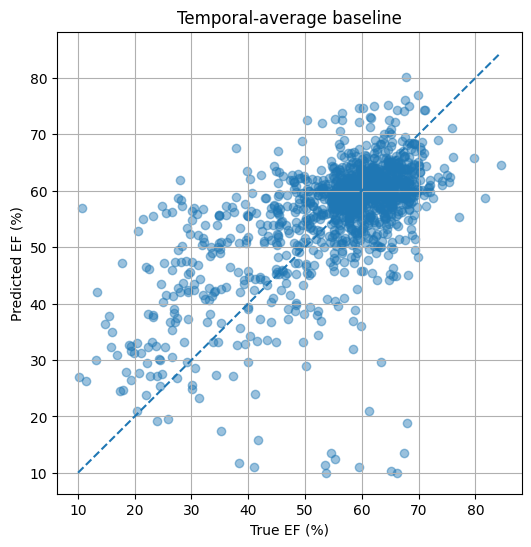

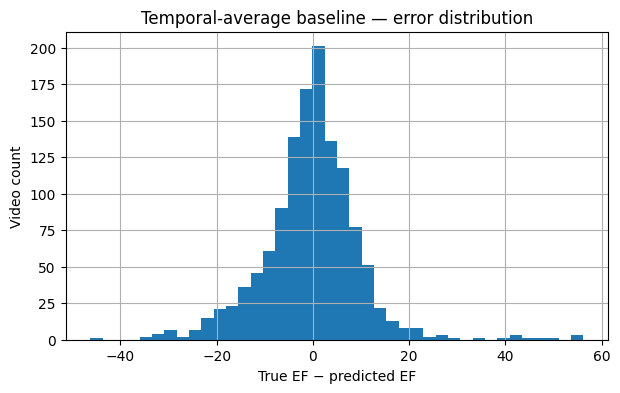

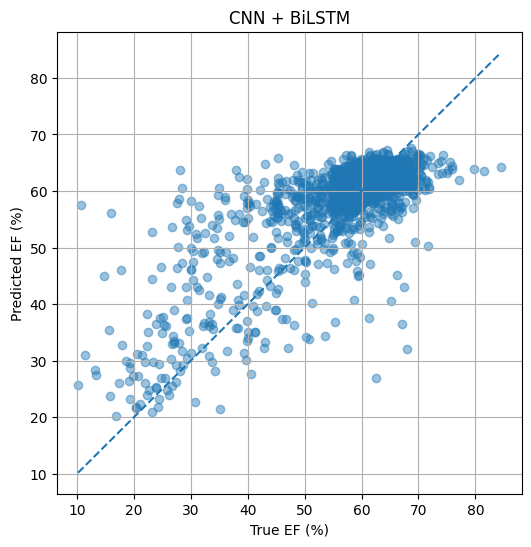

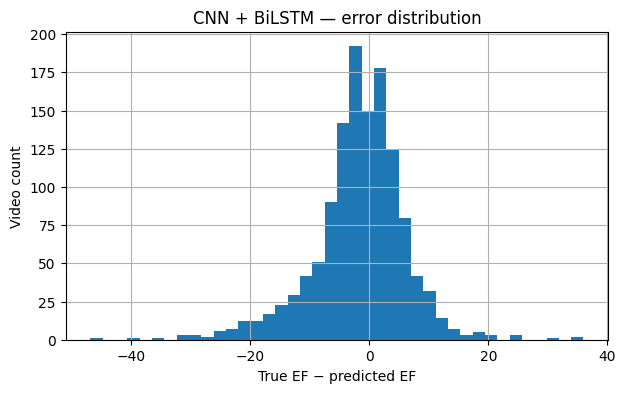

In [18]:
def plot_predictions(predictions_df, title):
    y_true = predictions_df["EF_true"].to_numpy()
    y_pred = predictions_df["EF_predicted"].to_numpy()

    low = min(y_true.min(), y_pred.min())
    high = max(y_true.max(), y_pred.max())

    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.45)
    plt.plot([low, high], [low, high], "--")
    plt.xlabel("True EF (%)")
    plt.ylabel("Predicted EF (%)")
    plt.title(title)
    plt.grid(True)
    plt.show()

    errors = y_true - y_pred
    plt.figure(figsize=(7, 4))
    plt.hist(errors, bins=40)
    plt.xlabel("True EF − predicted EF")
    plt.ylabel("Video count")
    plt.title(title + " — error distribution")
    plt.grid(True)
    plt.show()


plot_predictions(average_predictions, "Temporal-average baseline")
plot_predictions(bilstm_predictions, "CNN + BiLSTM")

In [19]:
def checkpoint_size_mb(path):
    return os.path.getsize(path) / (1024 ** 2)


efficiency_df = pd.DataFrame([
    {
        "Model": "MobileNetV3-Small + Average Pooling",
        "Trainable_parameters": count_parameters(average_model),
        "Checkpoint_MB": checkpoint_size_mb(average_checkpoint),
        "Test_MAE": average_metrics["MAE"],
        "Test_RMSE": average_metrics["RMSE"],
        "Forward_ms_per_video": average_metrics["Forward_ms_per_video"]
    },
    {
        "Model": "MobileNetV3-Small + BiLSTM",
        "Trainable_parameters": count_parameters(bilstm_model),
        "Checkpoint_MB": checkpoint_size_mb(bilstm_checkpoint),
        "Test_MAE": bilstm_metrics["MAE"],
        "Test_RMSE": bilstm_metrics["RMSE"],
        "Forward_ms_per_video": bilstm_metrics["Forward_ms_per_video"]
    }
])

display(efficiency_df.round(4))

efficiency_df.to_csv(
    OUTPUT_DIR / "model_efficiency_comparison.csv",
    index=False
)

,Model,Trainable_parameters,Checkpoint_MB,Test_MAE,Test_RMSE,Forward_ms_per_video
0,MobileNetV3-Small + Average Pooling,1000993,3.9513,6.9986,9.9941,2.3108
1,MobileNetV3-Small + BiLSTM,1682977,6.5538,5.6937,8.0518,2.3711


In [20]:
summary = {
    "dataset": "EchoNet-Dynamic",
    "task": "Video-level EF regression",
    "num_frames": NUM_FRAMES,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "train_videos": len(train_df),
    "validation_videos": len(val_df),
    "test_videos": len(test_df),
    "best_average_validation_MAE": float(average_history["val_mae"].min()),
    "best_bilstm_validation_MAE": float(bilstm_history["val_mae"].min()),
    "average_pooling_test_metrics": average_metrics,
    "bilstm_test_metrics": bilstm_metrics
}

with open(OUTPUT_DIR / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)

print(json.dumps(summary, indent=2, default=float))
print("\nAll outputs saved to:", OUTPUT_DIR)

{
  "dataset": "EchoNet-Dynamic",
  "task": "Video-level EF regression",
  "num_frames": 16,
  "image_size": 112,
  "batch_size": 4,
  "seed": 42,
  "train_videos": 7465,
  "validation_videos": 1288,
  "test_videos": 1277,
  "best_average_validation_MAE": 6.5056874126381015,
  "best_bilstm_validation_MAE": 5.443768595316396,
  "average_pooling_test_metrics": {
    "MAE": 6.998605371175003,
    "MSE": 99.88244778528671,
    "RMSE": 9.994120660932943,
    "R2": 0.33172307335953877,
    "Pearson_r": 0.614224974494916,
    "Within_5_EF_points_percent": 50.274079874706345,
    "Model": "mobilenetv3_average",
    "Test_videos": 1277,
    "Forward_seconds_total": 2.950869520995184,
    "Forward_ms_per_video": 2.3107827102546468
  },
  "bilstm_test_metrics": {
    "MAE": 5.693735664863556,
    "MSE": 64.83181029588074,
    "RMSE": 8.051820309462993,
    "R2": 0.5662340692109998,
    "Pearson_r": 0.7644739335895996,
    "Within_5_EF_points_percent": 59.514487079091616,
    "Model": "mobilenetv3

In [22]:
# Run 1
NUM_FRAMES = 8
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/EchoNet_EF_Experiment_8frames"
)

# Run 2
NUM_FRAMES = 16
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/EchoNet_EF_Experiment_16frames"
)

# Run 3
NUM_FRAMES = 30
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/EchoNet_EF_Experiment_30frames"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)